In [1]:
import os, mlflow
from dotenv import load_dotenv

load_dotenv("../../.env")
os.environ["MLFLOW_TRACKING_USERNAME"] = "Sharanya-0224"
os.environ["MLFLOW_TRACKING_PASSWORD"] = os.environ["DAGSHUB_USER_TOKEN"]

mlflow.set_tracking_uri("https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow")
exp = mlflow.set_experiment("rain_anomaly_leads")
print(mlflow.get_tracking_uri())
print(exp.experiment_id, exp.name)

/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow
3 rain_anomaly_leads


In [5]:
import json, pandas as pd

df = pd.read_csv("../data/processed/04_model_dataset_final.csv")
with open("../data/processed/feature_list.json") as f:
    features = json.load(f)["features"]

print(df.shape, len(features))
print(df[features].isna().sum().sum())

(250339, 39) 22
0


Note: all the below baselines are initially being trained on lead 3 ( anamoly prediction 3 months ahead)

Baseline 1: Climatology

Idea: always forecast a normal month for that cell and calendar month.

- Anomaly: target = observed rainfall − climatological mean (cell, calendar month)
- Standardised: z = target / sd, with sd floored at 5 mm
- Forecast: ẑ(t+3) = 0, so predicted rainfall = climatological mean
- MSE skill score = 1 − MSE(model) / MSE(climatology), where MSE(climatology) = mean(z²){R² = 1 − SSE / SST. It is computed against the mean of the observations. MSE skill is the same idea computed against z = 0 (climatology), so it is the more honest number here.}
- Skill = 0 by definition. Every later model must beat this.
- ACC = anamoly correlation coefficient (pearsons coorelation) bw predicted and observed anamolies. It asks whether the model gets the direction and pattern right (wetter vs drier than normal), ignoring the size of the error. MSE, RMSE and R² also penalise the size of the error
- Metrics reported on val, with and without |z| > 6 rows

In [6]:
import numpy as np

H = 3
zc, tc, sc = f"z_t+{H}", f"target_t+{H}", f"sd_t+{H}"

d = df.dropna(subset=[zc]).copy()
tr = d[d["split"] == "train"]
va = d[d["split"] == "val"]
print("rows train/val:", len(tr), len(va))

def metrics(y, p):
    mse = np.mean((y - p) ** 2)
    return {"mse": mse,
            "rmse": np.sqrt(mse),
            "mae": np.mean(np.abs(y - p)),
            "mse_skill": 1 - mse / np.mean(y ** 2),   # vs climatology (z=0)
            "acc": np.corrcoef(y, p)[0, 1] if np.std(p) > 0 else np.nan}

def report(name, p_z, part=va):
    y = part[zc].values
    keep = np.abs(y) <= 6
    out = {"all": metrics(y, p_z), "no_outliers": metrics(y[keep], p_z[keep])}
    mm = np.sqrt(np.mean((part[tc].values - p_z * part[sc].values) ** 2))
    print(name, "| RMSE mm:", round(mm, 2))
    print(pd.DataFrame(out).T.round(4))

report("climatology", np.zeros(len(va)))

rows train/val: 173056 36477
climatology | RMSE mm: 77.12
                mse    rmse     mae  mse_skill  acc
all          1.4741  1.2141  0.7773        0.0  NaN
no_outliers  1.0591  1.0291  0.7416        0.0  NaN


In [8]:
import glob, subprocess, importlib.util

print("psutil installed:", importlib.util.find_spec("psutil") is not None)
print("git commit:", subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip())
print(glob.glob("../data/processed/04_model_dataset_final*.dvc"))

psutil installed: True
git commit: 84de307
['../data/processed/04_model_dataset_final.csv.dvc']


In [7]:
import mlflow, subprocess, tempfile, os

MD5 = "f75fec0423508e189c4b2817b123cc99"
GIT = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()

def season(m):
    return {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
            6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}[m]

def region(lat):
    return "south" if lat < 15 else ("central" if lat < 24 else "north")

def log_run(run_name, p_z, params=None, part=None):
    part = va if part is None else part
    y = part[zc].values
    keep = np.abs(y) <= 6
    m_all, m_no = metrics(y, p_z), metrics(y[keep], p_z[keep])
    rmse_mm = np.sqrt(np.mean((part[tc].values - p_z * part[sc].values) ** 2))

    res = {f"{k}_all": v for k, v in m_all.items()}
    res.update({f"{k}_no_outliers": v for k, v in m_no.items()})
    res["rmse_mm"] = rmse_mm

    # by season (row month) and by region (lat band), val only
    for name, groups in [("season", part["month"].map(season)),
                         ("region", part["lat"].map(region))]:
        for g in groups.unique():
            idx = (groups == g).values
            mg = metrics(y[idx], p_z[idx])
            res[f"mse_skill_{name}_{g}"] = mg["mse_skill"]
            res[f"rmse_{name}_{g}"] = mg["rmse"]

    with mlflow.start_run(run_name=run_name, log_system_metrics=True):
        mlflow.log_params({"lead": H, "model": run_name, "n_features": len(features),
                           "clip_setting": "none", **(params or {})})
        mlflow.log_metrics({k: float(v) for k, v in res.items() if not np.isnan(v)})
        mlflow.set_tags({"git_commit": GIT, "dataset_md5": MD5, "split_evaluated": "val"})

        mlflow.log_artifact("../data/processed/feature_list.json")
        out = part[["year", "month", "lat", "lon", zc, tc, sc]].copy()
        out["pred_z"] = p_z
        out["pred_mm"] = p_z * part[sc].values
        with tempfile.TemporaryDirectory() as tmp:
            fp = os.path.join(tmp, f"val_predictions_{run_name}_lead{H}.csv")
            out.to_csv(fp, index=False)
            mlflow.log_artifact(fp)
    return res

res = log_run("climatology", np.zeros(len(va)))
print(round(res["mse_skill_all"], 4), round(res["rmse_mm"], 2))

2026/11/11 10:08:04 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:08:04 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run climatology at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/3ffc601c9eab487394263b5f65078c53
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4


2026/11/11 10:08:15 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:08:15 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


0.0 77.12


In [9]:
d2 = df.sort_values(["lat", "lon", "t"]).copy()
g = d2.groupby(["lat", "lon"])
d2["prev_t"] = g["t"].shift(1)
d2["prev_target1"] = g["target_t+1"].shift(1)
d2["prev_z1"] = g["z_t+1"].shift(1)

ok = d2[d2["t"] - d2["prev_t"] == 1].dropna(subset=["prev_target1"])
print("rows checked:", len(ok))
print("lag_1 vs prev target_t+1, max abs diff:", (ok["rainfall_anomaly_lag_1"] - ok["prev_target1"]).abs().max())
print("lag_1 vs prev z_t+1, max abs diff:", (ok["rainfall_anomaly_lag_1"] - ok["prev_z1"]).abs().max())
print(ok["rainfall_anomaly_lag_1"].describe().round(3))

rows checked: 249465
lag_1 vs prev target_t+1, max abs diff: 0.0
lag_1 vs prev z_t+1, max abs diff: 1780.805766611309
count    249465.000
mean          0.689
std          72.408
min        -874.501
25%         -19.424
50%          -3.995
75%          12.219
max        1784.011
Name: rainfall_anomaly_lag_1, dtype: float64


In [11]:
mlflow.set_system_metrics_sampling_interval(1)

Baseline 2: Persistance

- Logic: “next month’s anomaly = this month’s anomaly.”
- Formula: ẑ(t+h) = z_origin, where z_origin = rainfall_anomaly_lag_1 / sd_origin
lag_1 is in mm, but the target is in z units (divided by the sd of the target month). 
- So you convert the origin anomaly using the sd of the origin’s calendar month (sd_origin, looked up via pm, the previous month).
- It’s a “no-skill-from-physics” baseline: it only asks whether anomalies stick around.

In [12]:
p_z = va["rainfall_anomaly_lag_1"].values / va[sc].values
report("persistence", p_z)
res = log_run("persistence", p_z, params={"rule": "lag_1 / sd_target"})
print(round(res["mse_skill_all"], 4), round(res["acc_all"], 4))

persistence | RMSE mm: 104.14
                 mse    rmse     mae  mse_skill     acc
all          17.5226  4.1860  2.1005   -10.8870  0.0272
no_outliers  17.1384  4.1399  2.0711   -15.1828  0.0197


2026/11/10 19:36:27 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 19:36:27 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run persistence at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/12a6f1437b0d4434ac1aeb9a5f321524
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3


2026/11/10 19:36:45 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 19:36:46 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


-10.887 0.0272


In [10]:
sd_lu = df.groupby(["lat", "lon", "month"])["sd_t+1"].agg(["min", "max"])
print("sd constant per cell-month:", np.allclose(sd_lu["min"], sd_lu["max"]))

tmp = va[["lat", "lon", "month"]].copy()
tmp["pm"] = (tmp["month"] - 2) % 12 + 1
lu = sd_lu["min"].rename("sd_origin").reset_index().rename(columns={"month": "pm"})
sd_origin = tmp.merge(lu, on=["lat", "lon", "pm"], how="left")["sd_origin"].values

p_z = va["rainfall_anomaly_lag_1"].values / sd_origin

chk = d2.loc[va.index, "prev_z1"].values
m = ~np.isnan(chk)
print("max abs diff vs previous row z_t+1:", np.abs(p_z[m] - chk[m]).max(), "| NaN preds:", np.isnan(p_z).sum())

report("persistence_z", p_z)
res = log_run("persistence_z", p_z, params={"rule": "lag_1 / sd_origin_month"})

sd constant per cell-month: True
max abs diff vs previous row z_t+1: 3.2532322821558948 | NaN preds: 0
persistence_z | RMSE mm: 113.84
                mse    rmse     mae  mse_skill     acc
all          2.8762  1.6959  1.0777    -0.9512  0.0247
no_outliers  2.4802  1.5749  1.0442    -1.3419  0.0227


2026/11/11 10:09:08 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:09:08 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run persistence_z at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/8c1f6bae9ef04b65acc4d76e2dd37d0c
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4


2026/11/11 10:09:20 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:09:21 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


In [14]:
prev = d2.loc[va.index, "prev_t"].values
cons = (va["t"].values - prev == 1) & m
diff = np.abs(p_z[cons] - chk[cons])
print("consecutive rows:", cons.sum(), "| max diff:", diff.max(), "| rows with diff > 1e-6:", (diff > 1e-6).sum())

consecutive rows: 36192 | max diff: 3.552713678800501e-15 | rows with diff > 1e-6: 0


The first check showed max diff 3.25 because it included non-consecutive rows (gaps in the data), where “previous row” isn’t actually the previous month.
The second check restricted to consecutive rows (t - prev_t == 1): max diff 3.6e-15, so the reconstruction is exact. Nothing was being “minimised”; the 3.25 was just gap rows polluting the comparison.
Verdict: correct. The implementation is verified.

Baseline 3: Damped persistence

Logic: shrink the persistence forecast by the actual correlation. (The aim is to measure how much of the origin anomaly still carries into the lead-3 target, and to shrink the forecast by exactly that amount.)
Formula: ẑ(t+h) = β(h, m) · z_origin, with β = Σ(z_origin · z_target) / Σ(z_origin²), fit on train only, one β per lead h and calendar month m.
Since correlation ≈ 0.02, β will be near 0, so predictions shrink toward climatology (z = 0). Expect MSE skill ≈ 0 or slightly positive, never much worse than climatology.

In [17]:
import matplotlib.pyplot as plt

LEAD = 3
assert H == LEAD and zc == f"z_t+{LEAD}", (H, LEAD, zc)

# 1) fit beta per calendar month on train only
tr = df[df["split"] == "train"]
x_tr, y_tr = origin_z(tr), tr[zc].values
ok = ~np.isnan(x_tr) & ~np.isnan(y_tr)
mon = tr["month"].values

beta, n_fit = {}, {}
for m_ in range(1, 13):
    k = ok & (mon == m_)
    n_fit[m_] = int(k.sum())
    beta[m_] = float((x_tr[k] * y_tr[k]).sum() / (x_tr[k] ** 2).sum())
b = pd.Series(beta)
print(f"beta: min {b.min():.4f} | max {b.max():.4f} | mean {b.mean():.4f} | mean|beta| {b.abs().mean():.4f}")
print("train rows per month: min", min(n_fit.values()), "| max", max(n_fit.values()))

# 2) predict on val
pz_damped = va["month"].map(beta).values * origin_z(va)
print("NaN preds:", np.isnan(pz_damped).sum())

# 3) log the run
name = f"damped_persistence_z_lead{LEAD}"
params = {
    "model_type": "damped_persistence",
    "target": zc,
    "predictor": "rainfall_anomaly_lag_1 / sd_origin_month",
    "formula": "z_hat = beta[m] * z_origin",
    "beta_estimator": "least squares through origin: sum(x*y)/sum(x^2)",
    "beta_grouping": "calendar month of the target row",
    "fit_split": "train only",
    "n_beta": 12,
    "n_train_rows_fit": int(ok.sum()),
    "beta_mean": round(b.mean(), 4),
    "beta_abs_mean": round(b.abs().mean(), 4),
    **{f"beta_m{k:02d}": round(v, 4) for k, v in beta.items()},
}
report(name, pz_damped)
res = log_run(name, pz_damped, params=params)
print({k: round(float(res[k]), 4) for k in ["mse_skill_all", "mse_skill_no_outliers", "acc_all", "rmse_mm"]})

# 4) attach beta artifacts to the same run
run_id = mlflow.last_active_run().info.run_id
beta_tbl = pd.DataFrame({"month": list(beta), "beta": list(beta.values()),
                         "n_train_rows": [n_fit[k] for k in beta]})
with mlflow.start_run(run_id=run_id):
    mlflow.log_table(beta_tbl, f"beta_table_lead{LEAD}.json")
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(beta_tbl["month"], beta_tbl["beta"])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("target-row month"); ax.set_ylabel("beta")
    ax.set_title(f"Damped persistence beta, lead {LEAD}")
    mlflow.log_figure(fig, f"beta_by_month_lead{LEAD}.png")
    plt.close(fig)
print("run:", run_id)

beta: min -0.0235 | max 0.1290 | mean 0.0292 | mean|beta| 0.0359
train rows per month: min 14347 | max 14642
NaN preds: 0
damped_persistence_z_lead3 | RMSE mm: 77.05
                mse    rmse     mae  mse_skill     acc
all          1.4764  1.2151  0.7776    -0.0015  0.0068
no_outliers  1.0613  1.0302  0.7420    -0.0021  0.0074


2026/11/10 20:36:21 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 20:36:21 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run damped_persistence_z_lead3 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/d1774247564c4b88922ea9caa266b613
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3


2026/11/10 20:36:44 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 20:36:46 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


{'mse_skill_all': -0.0015, 'mse_skill_no_outliers': -0.0021, 'acc_all': 0.0068, 'rmse_mm': 77.0526}
🏃 View run damped_persistence_z_lead3 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/d1774247564c4b88922ea9caa266b613
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3
run: d1774247564c4b88922ea9caa266b613


Baseline ML model 1: 
Aim: Ridge regression on the 22 features predicts z_t+3 directly. The logic is a linear combination of the features, ẑ = w·x + b, with the weights shrunk by an L2 penalty: minimise Σ(z − w·x − b)² + α‖w‖². The scaler and the weights are fit on train only, α is chosen on val, and test stays untouched. This is the main linear baseline, so it shows whether lags, ENSO and IOD add any skill beyond persistence. The cell also adds the per-cell ACC map, which the plan needed and log_run doesn’t log yet.

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt

assert H == LEAD and zc == f"z_t+{LEAD}", (H, LEAD, zc)

# 1) train-only data, drop NaN targets
tr = df[df["split"] == "train"]
y_tr = tr[zc].values
ok = ~np.isnan(y_tr)
X_tr, y_fit = tr.loc[ok, features].values, y_tr[ok]
X_va = va[features].values
print("train rows:", ok.sum(), "| val rows:", len(va), "| features:", len(features))

# 2) pick alpha on val (compact table)
rows = []
for a in [1, 10, 100, 1e3, 1e4, 1e5]:
    p = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_tr, y_fit)
    pv = p.predict(X_va)
    rows.append((a, metrics(va[zc].values, pv)["mse_skill"]))
grid = pd.DataFrame(rows, columns=["alpha", "val_mse_skill"])
print(grid.round(5).to_string(index=False))
best_a = float(grid.loc[grid["val_mse_skill"].idxmax(), "alpha"])
print("best alpha:", best_a)

# 3) final fit + predict
pipe = make_pipeline(StandardScaler(), Ridge(alpha=best_a)).fit(X_tr, y_fit)
pz_ridge = pipe.predict(X_va)
coef = pd.DataFrame({"feature": features, "coef_std": pipe[-1].coef_})
coef["abs"] = coef["coef_std"].abs()
coef = coef.sort_values("abs", ascending=False)
print(coef.head(8)[["feature", "coef_std"]].round(4).to_string(index=False))

# 4) log run
name = f"ridge_lead{LEAD}"
params = {
    "model_type": "ridge",
    "target": zc,
    "formula": "z_hat = w . standardised(x) + b; min sum(z - z_hat)^2 + alpha*|w|^2",
    "alpha": best_a,
    "alpha_grid": "1,10,100,1e3,1e4,1e5",
    "alpha_selected_on": "val mse_skill",
    "scaler": "StandardScaler fit on train only",
    "fit_split": "train only",
    "clip_setting": "none",
    "n_train_rows_fit": int(ok.sum()),
    "intercept": round(float(pipe[-1].intercept_), 5),
}
report(name, pz_ridge)
res = log_run(name, pz_ridge, params=params)
print({k: round(float(res[k]), 4) for k in ["mse_skill_all", "mse_skill_no_outliers", "acc_all", "rmse_mm"]})

# 5) per-cell ACC map + coefficient artifacts, attached to the same run
cell = va[["lat", "lon"]].copy()
cell["p"], cell["y"] = pz_ridge, va[zc].values
acc_cell = (cell.groupby(["lat", "lon"])
            .apply(lambda g: np.corrcoef(g["p"], g["y"])[0, 1], include_groups=False)
            .rename("acc").reset_index())
print("per-cell ACC: mean", round(acc_cell["acc"].mean(), 4),
      "| min", round(acc_cell["acc"].min(), 4), "| max", round(acc_cell["acc"].max(), 4),
      "| cells > 0:", int((acc_cell["acc"] > 0).sum()), "/", len(acc_cell))

run_id = mlflow.last_active_run().info.run_id
with mlflow.start_run(run_id=run_id):
    mlflow.log_metrics({"acc_cell_mean": float(acc_cell["acc"].mean()),
                        "acc_cell_frac_positive": float((acc_cell["acc"] > 0).mean())})
    mlflow.log_table(grid, f"alpha_grid_lead{LEAD}.json")
    mlflow.log_table(coef[["feature", "coef_std"]], f"coefficients_lead{LEAD}.json")

    fig, ax = plt.subplots(figsize=(6, 5))
    sc_ = ax.scatter(acc_cell["lon"], acc_cell["lat"], c=acc_cell["acc"],
                     cmap="RdBu_r", vmin=-0.4, vmax=0.4, s=60, marker="s")
    plt.colorbar(sc_, label="ACC"); ax.set_title(f"Per-cell ACC, ridge, lead {LEAD}")
    mlflow.log_figure(fig, f"acc_map_lead{LEAD}.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(6, 5))
    c = coef.iloc[::-1]
    ax.barh(c["feature"], c["coef_std"]); ax.set_title(f"Ridge coefficients (standardised), lead {LEAD}")
    mlflow.log_figure(fig, f"feature_importance_lead{LEAD}.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.scatter(va[zc].values, pz_ridge, s=2, alpha=0.2)
    ax.set_xlabel("observed z"); ax.set_ylabel("predicted z"); ax.set_title("Predicted vs observed")
    mlflow.log_figure(fig, f"pred_vs_obs_lead{LEAD}.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(5, 3))
    ax.hist(va[zc].values - pz_ridge, bins=100, range=(-6, 6)); ax.set_title("Residuals (z)")
    mlflow.log_figure(fig, f"residuals_lead{LEAD}.png"); plt.close(fig)

    try:
        mlflow.sklearn.log_model(pipe, "model")
    except Exception as e:
        print("model logging failed:", type(e).__name__, str(e)[:150])
print("run:", run_id)

train rows: 173056 | val rows: 36477 | features: 22
   alpha  val_mse_skill
     1.0        0.00437
    10.0        0.00437
   100.0        0.00432
  1000.0        0.00393
 10000.0        0.00263
100000.0        0.00220
best alpha: 1.0
                    feature  coef_std
               nino34_lag_2   -0.2144
               nino34_lag_3    0.1808
               nino34_lag_1    0.0470
rainfall_anomaly_rolling_6m    0.0432
                  dmi_lag_1    0.0331
                  dmi_lag_2   -0.0234
                  month_cos   -0.0200
  temperature_anomaly_lag_2    0.0085
ridge_lead3 | RMSE mm: 76.5
                mse    rmse     mae  mse_skill     acc
all          1.4677  1.2115  0.7756     0.0044  0.0650
no_outliers  1.0530  1.0262  0.7399     0.0057  0.0772


2026/11/10 20:42:39 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 20:42:39 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run ridge_lead3 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/559c3a159cf64b7aa8feb368c537e737
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3


2026/11/10 20:42:49 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 20:42:50 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


{'mse_skill_all': 0.0044, 'mse_skill_no_outliers': 0.0057, 'acc_all': 0.065, 'rmse_mm': 76.4963}
per-cell ACC: mean 0.0252 | min -0.3754 | max 0.3727 | cells > 0: 173 / 283


2026/11/10 20:43:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run ridge_lead3 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/559c3a159cf64b7aa8feb368c537e737
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3
run: 559c3a159cf64b7aa8feb368c537e737


In [19]:
y_va = va[zc].values
rows = []
for kind, grp in [("season", va["month"].map(season)), ("region", va["lat"].map(region))]:
    for g in sorted(grp.unique()):
        i = (grp == g).values
        mg = metrics(y_va[i], pz_ridge[i])
        rows.append((kind, g, int(i.sum()), mg["mse_skill"], mg["rmse"], mg["acc"]))
bytab = pd.DataFrame(rows, columns=["kind", "group", "n", "mse_skill", "rmse_z", "acc"])
print(bytab.round(4).to_string(index=False))

try:
    print("per-cell ACC: mean", round(acc_cell["acc"].mean(), 4),
          "| min", round(acc_cell["acc"].min(), 4), "| max", round(acc_cell["acc"].max(), 4),
          "| cells > 0:", int((acc_cell["acc"] > 0).sum()), "/", len(acc_cell))
except NameError:
    print("acc_cell not defined: step 5 of the ridge cell did not run")

run_id = mlflow.last_active_run().info.run_id
with mlflow.start_run(run_id=run_id):
    mlflow.log_metrics({f"acc_{r.kind}_{r.group}": float(r.acc) for r in bytab.itertuples()
                        if not np.isnan(r.acc)})
    mlflow.log_table(bytab, f"by_group_metrics_lead{LEAD}.json")
print("run:", run_id)

  kind   group     n  mse_skill  rmse_z    acc
season     DJF  9046     0.0024  1.4463 0.0690
season     JJA  9335     0.0126  1.0739 0.1116
season     MAM  9329    -0.0008  1.2067 0.0114
season     SON  8767     0.0062  1.0820 0.0857
region central 15609     0.0032  1.2540 0.0506
region   north 17256     0.0058  1.0575 0.0765
region   south  3612     0.0047  1.6382 0.0243
per-cell ACC: mean 0.0252 | min -0.3754 | max 0.3727 | cells > 0: 173 / 283
🏃 View run ridge_lead3 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/559c3a159cf64b7aa8feb368c537e737
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3
run: 559c3a159cf64b7aa8feb368c537e737


                            mse_skill  mse_skill_no_out     acc   rmse_mm
name                                                                     
climatology                    0.0000            0.0000     NaN   77.1221
persistence_z                 -0.9512           -1.3419  0.0247  113.8411
damped_persistence_z_lead3    -0.0015           -0.0021  0.0068   77.0526
ridge_lead3                    0.0044            0.0057  0.0650   76.4963


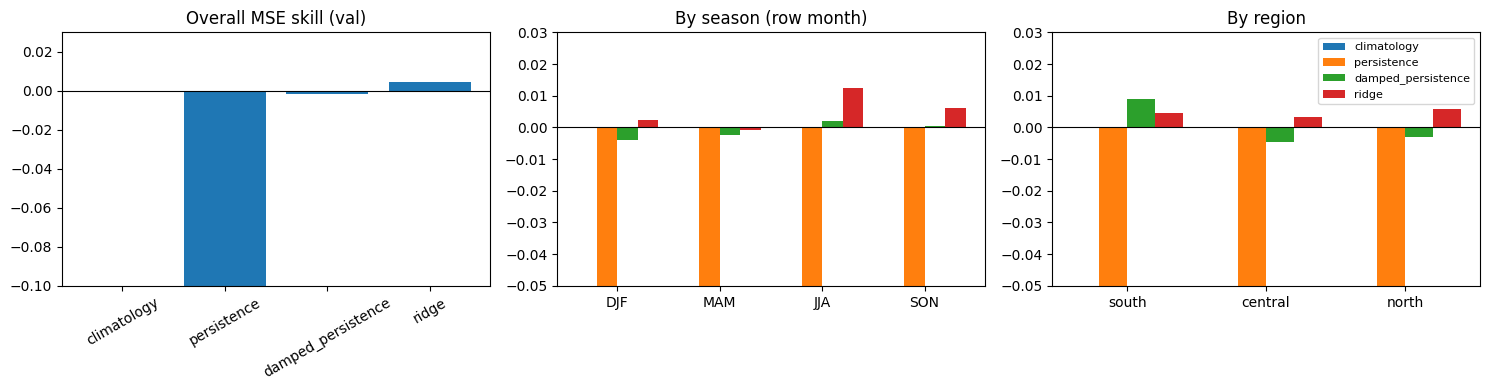

🏃 View run baseline_comparison_lead3 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/f4564767b94b4ee98155794aec1efd56
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3


In [20]:
import matplotlib.pyplot as plt

EXP_ID = mlflow.get_experiment_by_name(mlflow.get_experiment(
    mlflow.last_active_run().info.experiment_id).name).experiment_id
runs = mlflow.search_runs(experiment_ids=[EXP_ID])
runs["name"] = runs["tags.mlflow.runName"]

wanted = ["climatology", "persistence_z", f"damped_persistence_z_lead{LEAD}", f"ridge_lead{LEAD}"]
# add later: f"lightgbm_lead{LEAD}"
runs = (runs[runs["name"].isin(wanted)].sort_values("start_time")
        .drop_duplicates("name", keep="last").set_index("name").reindex(
            [w for w in wanted if w in set(runs["name"])]))

seasons, regions = ["DJF", "MAM", "JJA", "SON"], ["south", "central", "north"]
col = lambda k: runs[f"metrics.{k}"]

summary = pd.DataFrame({"mse_skill": col("mse_skill_all"), "mse_skill_no_out": col("mse_skill_no_outliers"),
                        "acc": col("acc_all"), "rmse_mm": col("rmse_mm")})
print(summary.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
labels = [n.replace(f"_lead{LEAD}", "").replace("_z", "") for n in runs.index]

ax[0].bar(labels, col("mse_skill_all").values); ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Overall MSE skill (val)"); ax[0].tick_params(axis="x", rotation=30)
ax[0].set_ylim(-0.1, 0.03)  # persistence (-0.95) is clipped on purpose

for a, keys, names, title in [(ax[1], [f"mse_skill_season_{s}" for s in seasons], seasons, "By season (row month)"),
                              (ax[2], [f"mse_skill_region_{r}" for r in regions], regions, "By region")]:
    w = 0.8 / len(runs)
    for j, (n, lab) in enumerate(zip(runs.index, labels)):
        a.bar(np.arange(len(keys)) + j * w, [runs.loc[n, f"metrics.{k}"] for k in keys], w, label=lab)
    a.set_xticks(np.arange(len(keys)) + 0.4 - w / 2); a.set_xticklabels(names)
    a.axhline(0, color="k", lw=0.8); a.set_title(title); a.set_ylim(-0.05, 0.03)
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

with mlflow.start_run(run_name=f"baseline_comparison_lead{LEAD}"):
    mlflow.set_tags({"git_commit": GIT, "dataset_md5": MD5, "split_evaluated": "val"})
    mlflow.log_param("runs_compared", ",".join(runs.index))
    mlflow.log_figure(fig, f"baseline_comparison_lead{LEAD}.png")
    mlflow.log_table(summary.reset_index(), f"baseline_summary_lead{LEAD}.json")
plt.close(fig)

Inference from the comparison graph

- Ridge is the only model clearly above climatology. Overall skill is small but positive. Persistence is far below zero and is cut off at the bottom of the chart (its true value is about -0.95). Damped persistence is almost exactly 0.
- Ridge’s skill is seasonal. It is best in JJA (the monsoon) and also positive in SON. DJF is barely positive and MAM is about zero or slightly negative. So the model’s skill comes from the monsoon and post-monsoon.
- Ridge is positive in all three regions, but weakly. It is strongest in the north. In the south, damped persistence is better (about 0.009 vs 0.004). That suggests southern rainfall has more month-to-month memory than the ENSO/IOD signal can explain.
- All differences are tiny. The best bar is about 0.012, so no model is yet good at this lead(i.e target anamoly is 3 months ahead). LightGBM is the next test of whether nonlinear season and region effects add anything.

Including below two metrics from next runs:
What “accuracy” means here

- Tercile accuracy: A rainfall anomaly is a number, so plain accuracy (% correct) doesn’t apply. The closest version is tercile accuracy. I split every anomaly into three classes: drier than normal (z < -0.43), near normal, and wetter than normal (z > +0.43). Each class holds about a third of the data. Tercile accuracy is the % of rows where the predicted class matches the observed class.
Random guessing gives about 33%, so 33% is the baseline, not 0%.
- HSS (Heidke skill score): is that accuracy rescaled so that 0 means “no better than chance” and 1 means perfect.

Baseline Model 2: LightGBM

Aim: test whether a nonlinear model beats Ridge at lead 3. The logic: gradient-boosted trees add small decision trees one after another. Each new tree fits the errors the previous trees left, so ẑ = Σ η · tree_k(x), where η is the learning rate. Trees can split on month and location, so they can learn “ENSO matters in JJA in the north only”. Settings are conservative because the signal is weak: small steps, large leaves (200 rows minimum) and row/column subsampling. The number of trees is chosen by early stopping on val. Train data is train only, and test stays untouched.

In [23]:
cells = df[["lat", "lon"]].drop_duplicates()
print("unique cells:", len(cells))
print("per split:", df.groupby("split")[["lat", "lon"]].apply(lambda g: len(g.drop_duplicates())).to_dict())
print("rows per cell: min", df.groupby(["lat", "lon"]).size().min(), "| max", df.groupby(["lat", "lon"]).size().max())

unique cells: 283
per split: {'test': 283, 'train': 283, 'val': 283}
rows per cell: min 535 | max 888


In [24]:
import lightgbm as lgb
import matplotlib.pyplot as plt

tr_fit = df[(df["split"] == "train")].dropna(subset=[zc])
va_fit = va

params_lgb = {
    "objective": "regression",
    "metric": "l2",
    "learning_rate": 0.02,
    "num_leaves": 12,
    "min_data_in_leaf": 500,
    "feature_fraction": 0.7,
    "bagging_fraction": 0.7,
    "bagging_freq": 1,
    "lambda_l2": 10,
    "seed": 42,
    "verbose": -1,
}

dtr = lgb.Dataset(tr_fit[features], label=tr_fit[zc])
dva = lgb.Dataset(va_fit[features], label=va_fit[zc], reference=dtr)

booster = lgb.train(
    params_lgb, dtr, num_boost_round=2000, valid_sets=[dva],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)],
)
best_it = booster.best_iteration
print("train rows:", len(tr_fit), "| val rows:", len(va_fit), "| best iteration:", best_it)

p_z = booster.predict(va_fit[features], num_iteration=best_it)
print("NaN preds:", np.isnan(p_z).sum())

name = f"lightgbm_lead{H}_v2"
report(name, p_z)
res = log_run(name, p_z, params={**params_lgb, "model_type": "lightgbm", "n_train_rows_fit": len(tr_fit),
                                 "num_boost_round_max": 2000, "early_stopping_rounds": 100,
                                 "best_iteration": best_it, "early_stopping_on": "val"})
print({k: round(float(res[k]), 4) for k in ["mse_skill_all", "mse_skill_no_outliers", "acc_all", "rmse_mm"]})

# attach importance table, figure and model to the same run
run_id = mlflow.last_active_run().info.run_id
imp = pd.DataFrame({"feature": features,
                    "gain_share": booster.feature_importance("gain") / booster.feature_importance("gain").sum()}
                   ).sort_values("gain_share", ascending=False)
print(imp.head(10).round(4).to_string(index=False))

with mlflow.start_run(run_id=run_id):
    mlflow.log_table(imp, f"feature_importance_lead{H}.json")
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.barh(imp["feature"][::-1], imp["gain_share"][::-1])
    ax.set_xlabel("gain share")
    ax.set_title(f"LightGBM feature importance, lead {H}")
    fig.tight_layout()
    mlflow.log_figure(fig, f"feature_importance_lead{H}.png")
    plt.close(fig)
    mlflow.lightgbm.log_model(booster, artifact_path="model")
print("run:", run_id)

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[3]	valid_0's l2: 1.47438
train rows: 173056 | val rows: 36477 | best iteration: 3
NaN preds: 0
lightgbm_lead3_v2 | RMSE mm: 77.11
                mse    rmse     mae  mse_skill     acc
all          1.4744  1.2142  0.7749    -0.0002  0.0066
no_outliers  1.0585  1.0289  0.7392     0.0005  0.0319


2026/11/10 21:35:58 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 21:35:58 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run lightgbm_lead3_v2 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/9d4ff079ebb5435b91fc249076995af0
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3


2026/11/10 21:36:13 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 21:36:13 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


{'mse_skill_all': -0.0002, 'mse_skill_no_outliers': 0.0005, 'acc_all': 0.0066, 'rmse_mm': 77.1101}
       feature  gain_share
  nino34_lag_1      0.2822
     month_cos      0.1845
  nino34_lag_3      0.1384
  nino34_lag_2      0.1332
nino34_mean_3m      0.0607
     dmi_lag_1      0.0538
     dmi_lag_2      0.0412
     month_sin      0.0359
   dmi_mean_3m      0.0357
     dmi_lag_3      0.0344


2026/11/10 21:36:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run lightgbm_lead3_v2 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/9d4ff079ebb5435b91fc249076995af0
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3
run: 9d4ff079ebb5435b91fc249076995af0


In [25]:
y = va_fit[zc].values
rows = []
for kind, grp in [("season", va_fit["month"].map(season)), ("region", va_fit["lat"].map(region))]:
    for g in sorted(grp.unique()):
        idx = (grp == g).values
        mg = metrics(y[idx], p_z[idx])
        rows.append({"kind": kind, "group": g, "n": int(idx.sum()),
                     "mse_skill": mg["mse_skill"], "rmse_z": mg["rmse"], "acc": mg["acc"]})
print(pd.DataFrame(rows).round(4).to_string(index=False))

acc_cell = (va_fit.assign(p=p_z).groupby(["lat", "lon"])
            .apply(lambda g: np.corrcoef(g[zc], g["p"])[0, 1] if g["p"].std() > 0 else np.nan))
print("per-cell ACC: mean", round(acc_cell.mean(), 4), "| min", round(acc_cell.min(), 4),
      "| max", round(acc_cell.max(), 4), "| cells > 0:", int((acc_cell > 0).sum()), "/", acc_cell.notna().sum())

  kind   group     n  mse_skill  rmse_z     acc
season     DJF  9046    -0.0016  1.4492 -0.1043
season     JJA  9335    -0.0006  1.0810  0.0297
season     MAM  9329    -0.0001  1.2063  0.0336
season     SON  8767     0.0028  1.0839  0.1412
region central 15609    -0.0007  1.2564 -0.0202
region   north 17256     0.0014  1.0598  0.0615
region   south  3612    -0.0020  1.6437 -0.0744
per-cell ACC: mean 0.0217 | min -0.2568 | max 0.3006 | cells > 0: 173 / 283


/tmp/ipykernel_18064/3434706708.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.corrcoef(g[zc], g["p"])[0, 1] if g["p"].std() > 0 else np.nan))


Clipping means capping extreme values at a limit. clip(-6, 6) takes any z-value above +6 and sets it to +6, and any below -6 and sets it to -6. Values between -6 and 6 are untouched.

Example: a z of 14 (a huge off-season rain event) becomes 6 in the training labels.

Why we do it: about 430 rows have |z| > 6. Because the error is squared, one row with z = 14 counts like 196 normal rows (14²), so the trees spend their effort chasing a few rare events instead of learning the normal pattern.

What stays the same:

It applies to the training target only. The model sees capped labels while learning.
Val is not clipped, so scores are still measured against the real values, including the extreme ones.
Features are not clipped, only the target label.

In [26]:
tr_fit = df[df["split"] == "train"].dropna(subset=[zc])
y_tr_clip = tr_fit[zc].clip(-6, 6)

params_lgb = {
    "objective": "regression", "metric": "l2",
    "learning_rate": 0.01, "num_leaves": 6, "max_depth": 3,
    "min_data_in_leaf": 2000, "feature_fraction": 0.7,
    "bagging_fraction": 0.7, "bagging_freq": 1,
    "lambda_l2": 100, "seed": 42, "verbose": -1,
}

dtr = lgb.Dataset(tr_fit[features], label=y_tr_clip)
dva = lgb.Dataset(va_fit[features], label=va_fit[zc], reference=dtr)

booster = lgb.train(params_lgb, dtr, num_boost_round=3000, valid_sets=[dva],
                    callbacks=[lgb.early_stopping(150), lgb.log_evaluation(500)])
best_it = booster.best_iteration
p_z = booster.predict(va_fit[features], num_iteration=best_it)
print("best iteration:", best_it, "| NaN preds:", np.isnan(p_z).sum())

name = f"lightgbm_lead{H}_v3_clip6"
report(name, p_z)
res = log_run(name, p_z, params={**params_lgb, "model_type": "lightgbm", "clip_setting": "train target clipped at +/-6",
                                 "n_train_rows_fit": len(tr_fit), "best_iteration": best_it,
                                 "early_stopping_on": "val"})
print({k: round(float(res[k]), 4) for k in ["mse_skill_all", "mse_skill_no_outliers", "acc_all", "rmse_mm"]})

Training until validation scores don't improve for 150 rounds
Early stopping, best iteration is:
[1]	valid_0's l2: 1.47447
best iteration: 1 | NaN preds: 0
lightgbm_lead3_v3_clip6 | RMSE mm: 77.11
                mse    rmse     mae  mse_skill     acc
all          1.4745  1.2143  0.7753    -0.0002 -0.0293
no_outliers  1.0589  1.0290  0.7396     0.0002  0.0071


2026/11/10 21:40:34 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 21:40:34 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run lightgbm_lead3_v3_clip6 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/92057b1e20c049e082581c91f3975e10
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3


2026/11/10 21:40:56 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 21:40:57 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


{'mse_skill_all': -0.0002, 'mse_skill_no_outliers': 0.0002, 'acc_all': -0.0293, 'rmse_mm': 77.112}


Why trees failed (simple version)

Trees learn rules from the training years (1951-2002), like “in this cell, in this month, when ENSO is high, rain is high.” The rain signal is very weak, so most of these rules are just noise. When tested on 2003-2013, the noisy rules fail, and the model does worse than guessing “normal.” That is why it stopped after 1 tree.

I need to take back one thing. I linked this to the “baseline uses all years” limitation, and that link was a guess. If anything, that limitation makes val look slightly better, not worse. Ignore that part.

Can we improve the metric?

No big jump is likely, because the signal at a 3-month lead is weak. But I can’t say there is no way. Your Ridge code is correct. The only fix is to write name="model" in the last log_model line to remove the warning. The real limit is that Ridge uses the same rule for every month, while ENSO affects India differently in each season.

Ideas, best first:

ENSO and IOD multiplied by the season (month_sin, month_cos). The model can then say “ENSO matters in monsoon months, not in winter.”
Fewer, cleaner features. The three ENSO lags are almost the same number, so they add noise.
Neighbour features, like the average anomaly of the whole region.
Separate models per season or region.


In [27]:
enso_cols = ["nino34_lag_1","nino34_lag_2","nino34_lag_3","nino34_mean_3m",
             "dmi_lag_1","dmi_lag_2","dmi_lag_3","dmi_mean_3m"]

def add_int(d):
    X = d[features].copy()
    for c in enso_cols:
        X[c + "_x_sin"] = d[c] * d["month_sin"]
        X[c + "_x_cos"] = d[c] * d["month_cos"]
    return X

trn = df[df["split"] == "train"].dropna(subset=[zc])
Xtr, Xva = add_int(trn), add_int(va)

rows = []
for a in [1, 10, 100, 1e3, 1e4]:
    p = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xtr, trn[zc])
    rows.append((a, metrics(va[zc].values, p.predict(Xva))["mse_skill"]))
grid2 = pd.DataFrame(rows, columns=["alpha", "val_mse_skill"])
print(grid2.round(5).to_string(index=False))

best_a = float(grid2.loc[grid2["val_mse_skill"].idxmax(), "alpha"])
pipe2 = make_pipeline(StandardScaler(), Ridge(alpha=best_a)).fit(Xtr, trn[zc])
p_z = pipe2.predict(Xva)

name = "ridge_lead3_v2_enso_x_season"
report(name, p_z)
res = log_run(name, p_z, params={"model_type": "ridge", "alpha": best_a,
                                 "extra_features": "enso/iod x month_sin/cos (16 added)",
                                 "n_features": Xtr.shape[1]})

  alpha  val_mse_skill
    1.0        0.00423
   10.0        0.00423
  100.0        0.00422
 1000.0        0.00413
10000.0        0.00381
ridge_lead3_v2_enso_x_season | RMSE mm: 76.69
                mse    rmse     mae  mse_skill     acc
all          1.4679  1.2116  0.7717     0.0042  0.0699
no_outliers  1.0516  1.0255  0.7360     0.0070  0.0847


2026/11/10 21:51:42 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 21:51:42 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run ridge_lead3_v2_enso_x_season at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3/runs/5af8a5e35c4f48acacf81194dd0beab8
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/3


2026/11/10 21:52:02 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 21:52:03 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


the above logic of ENSOx season did not result in any improvements
hence we retain the initial version of ridge regression which is the current best for lead 3 -> need to check how to improve results further.

below code runs the above process for lead 1 and 2 and makes each lead as a new mlflow experiment

In [28]:
LEAD = 1   # change to 2 for the lead 2 run
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

H = LEAD
zc, tc, sc = f"z_t+{H}", f"target_t+{H}", f"sd_t+{H}"
mlflow.set_experiment(f"rain_anomaly_lead{LEAD}")

d = df.dropna(subset=[zc])
tr = d[d["split"] == "train"]
va = d[d["split"] == "val"]
print("lead", H, "| train:", len(tr), "| val:", len(va))

lu = sd_lu["min"].rename("sd_origin").reset_index().rename(columns={"month": "pm"})
def origin_z(part):
    t = part[["lat", "lon", "month"]].copy()
    t["pm"] = (t["month"] - 2) % 12 + 1
    sd_o = t.merge(lu, on=["lat", "lon", "pm"], how="left")["sd_origin"].values
    return part["rainfall_anomaly_lag_1"].values / sd_o

summary = []
def run(name, p_z, params=None):
    report(name, p_z, part=va)
    r = log_run(name, p_z, params=params)
    summary.append({"run": name, **{k: round(float(r.get(k, np.nan)), 4)
                    for k in ["mse_skill_all", "mse_skill_no_outliers", "acc_all", "rmse_mm"]}})

# 1) climatology
run(f"climatology_lead{H}", np.zeros(len(va)))

# 2) persistence (latest anomaly in z units)
zo_tr, zo_va = origin_z(tr), origin_z(va)
print("NaN in origin z (val):", np.isnan(zo_va).sum())
run(f"persistence_z_lead{H}", zo_va, {"rule": "lag_1 / sd_origin_month"})

# 3) damped persistence, one beta per month of the row (train only)
y_tr = tr[zc].values
mon = tr["month"].values
beta = {m: float((zo_tr[mon == m] * y_tr[mon == m]).sum() / (zo_tr[mon == m] ** 2).sum()) for m in range(1, 13)}
print("beta mean:", round(np.mean(list(beta.values())), 4))
run(f"damped_persistence_z_lead{H}", va["month"].map(beta).values * zo_va,
    {"rule": "beta[month] * z_origin", "beta_fit": "train only"})

# 4) ridge v1 on the 22 features
X_tr, X_va = tr[features].values, va[features].values
rows = []
for a in [1, 10, 100, 1e3, 1e4, 1e5]:
    p = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_tr, y_tr)
    rows.append((a, metrics(va[zc].values, p.predict(X_va))["mse_skill"]))
grid = pd.DataFrame(rows, columns=["alpha", "val_mse_skill"])
print(grid.round(5).to_string(index=False))
best_a = float(grid.loc[grid["val_mse_skill"].idxmax(), "alpha"])
pipe = make_pipeline(StandardScaler(), Ridge(alpha=best_a)).fit(X_tr, y_tr)
run(f"ridge_lead{H}", pipe.predict(X_va),
    {"alpha": best_a, "scaler": "StandardScaler fit on train only", "n_train_rows_fit": len(tr)})

print(pd.DataFrame(summary).to_string(index=False))

# 5) LightGBM

import lightgbm as lgb

y_clip = tr[zc].clip(-6, 6)
params_lgb = {
    "objective": "regression", "metric": "l2",
    "learning_rate": 0.01, "num_leaves": 6, "max_depth": 3,
    "min_data_in_leaf": 2000, "feature_fraction": 0.7,
    "bagging_fraction": 0.7, "bagging_freq": 1,
    "lambda_l2": 100, "seed": 42, "verbose": -1,
}
dtr = lgb.Dataset(tr[features], label=y_clip)
dva = lgb.Dataset(va[features], label=va[zc], reference=dtr)
booster = lgb.train(params_lgb, dtr, num_boost_round=3000, valid_sets=[dva],
                    callbacks=[lgb.early_stopping(150), lgb.log_evaluation(500)])
best_it = booster.best_iteration
print("best iteration:", best_it)

run(f"lightgbm_v3_clip6_lead{H}", booster.predict(va[features], num_iteration=best_it),
    {**params_lgb, "model_type": "lightgbm", "clip_setting": "train target clipped at +/-6",
     "best_iteration": best_it, "early_stopping_on": "val"})
print(pd.DataFrame(summary).to_string(index=False))

2026/11/10 22:01:10 INFO mlflow.tracking.fluent: Experiment with name 'rain_anomaly_lead1' does not exist. Creating a new experiment.


lead 1 | train: 173106 | val: 36481
climatology_lead1 | RMSE mm: 76.53
                mse    rmse     mae  mse_skill  acc
all          1.4784  1.2159  0.7774        0.0  NaN
no_outliers  1.0568  1.0280  0.7410        0.0  NaN


2026/11/10 22:01:17 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 22:01:17 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run climatology_lead1 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/a1f2e690dfbd49f8b45ab4bf1ec81c2b
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4


2026/11/10 22:01:35 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 22:01:36 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


NaN in origin z (val): 0
persistence_z_lead1 | RMSE mm: 101.18
                mse    rmse     mae  mse_skill     acc
all          2.5465  1.5958  0.9942    -0.7225  0.1378
no_outliers  2.1823  1.4773  0.9625    -1.0650  0.1256


... (12 outputs left out)

2026/11/10 22:03:21 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 22:03:21 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run lightgbm_v3_clip6_lead1 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/c3dd5c352061404f9ab472b3e2ebd097
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4


2026/11/10 22:03:44 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 22:03:44 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


                       run  mse_skill_all  mse_skill_no_outliers  acc_all  rmse_mm
         climatology_lead1         0.0000                 0.0000      NaN  76.5346
       persistence_z_lead1        -0.7225                -1.0650   0.1378 101.1771
damped_persistence_z_lead1         0.0118                 0.0102   0.1121  75.6556
               ridge_lead1         0.0146                 0.0156   0.1229  73.8032
   lightgbm_v3_clip6_lead1         0.0045                 0.0094   0.0734  75.0809


In [29]:
LEAD = 2  # change to 2 for the lead 2 run
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

H = LEAD
zc, tc, sc = f"z_t+{H}", f"target_t+{H}", f"sd_t+{H}"
mlflow.set_experiment(f"rain_anomaly_lead{LEAD}")

d = df.dropna(subset=[zc])
tr = d[d["split"] == "train"]
va = d[d["split"] == "val"]
print("lead", H, "| train:", len(tr), "| val:", len(va))

lu = sd_lu["min"].rename("sd_origin").reset_index().rename(columns={"month": "pm"})
def origin_z(part):
    t = part[["lat", "lon", "month"]].copy()
    t["pm"] = (t["month"] - 2) % 12 + 1
    sd_o = t.merge(lu, on=["lat", "lon", "pm"], how="left")["sd_origin"].values
    return part["rainfall_anomaly_lag_1"].values / sd_o

summary = []
def run(name, p_z, params=None):
    report(name, p_z, part=va)
    r = log_run(name, p_z, params=params)
    summary.append({"run": name, **{k: round(float(r.get(k, np.nan)), 4)
                    for k in ["mse_skill_all", "mse_skill_no_outliers", "acc_all", "rmse_mm"]}})

# 1) climatology
run(f"climatology_lead{H}", np.zeros(len(va)))

# 2) persistence (latest anomaly in z units)
zo_tr, zo_va = origin_z(tr), origin_z(va)
print("NaN in origin z (val):", np.isnan(zo_va).sum())
run(f"persistence_z_lead{H}", zo_va, {"rule": "lag_1 / sd_origin_month"})

# 3) damped persistence, one beta per month of the row (train only)
y_tr = tr[zc].values
mon = tr["month"].values
beta = {m: float((zo_tr[mon == m] * y_tr[mon == m]).sum() / (zo_tr[mon == m] ** 2).sum()) for m in range(1, 13)}
print("beta mean:", round(np.mean(list(beta.values())), 4))
run(f"damped_persistence_z_lead{H}", va["month"].map(beta).values * zo_va,
    {"rule": "beta[month] * z_origin", "beta_fit": "train only"})

# 4) ridge v1 on the 22 features
X_tr, X_va = tr[features].values, va[features].values
rows = []
for a in [1, 10, 100, 1e3, 1e4, 1e5]:
    p = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_tr, y_tr)
    rows.append((a, metrics(va[zc].values, p.predict(X_va))["mse_skill"]))
grid = pd.DataFrame(rows, columns=["alpha", "val_mse_skill"])
print(grid.round(5).to_string(index=False))
best_a = float(grid.loc[grid["val_mse_skill"].idxmax(), "alpha"])
pipe = make_pipeline(StandardScaler(), Ridge(alpha=best_a)).fit(X_tr, y_tr)
run(f"ridge_lead{H}", pipe.predict(X_va),
    {"alpha": best_a, "scaler": "StandardScaler fit on train only", "n_train_rows_fit": len(tr)})

print(pd.DataFrame(summary).to_string(index=False))

# 5) LightGBM

import lightgbm as lgb

y_clip = tr[zc].clip(-6, 6)
params_lgb = {
    "objective": "regression", "metric": "l2",
    "learning_rate": 0.01, "num_leaves": 6, "max_depth": 3,
    "min_data_in_leaf": 2000, "feature_fraction": 0.7,
    "bagging_fraction": 0.7, "bagging_freq": 1,
    "lambda_l2": 100, "seed": 42, "verbose": -1,
}
dtr = lgb.Dataset(tr[features], label=y_clip)
dva = lgb.Dataset(va[features], label=va[zc], reference=dtr)
booster = lgb.train(params_lgb, dtr, num_boost_round=3000, valid_sets=[dva],
                    callbacks=[lgb.early_stopping(150), lgb.log_evaluation(500)])
best_it = booster.best_iteration
print("best iteration:", best_it)

run(f"lightgbm_v3_clip6_lead{H}", booster.predict(va[features], num_iteration=best_it),
    {**params_lgb, "model_type": "lightgbm", "clip_setting": "train target clipped at +/-6",
     "best_iteration": best_it, "early_stopping_on": "val"})
print(pd.DataFrame(summary).to_string(index=False))

2026/11/10 22:07:11 INFO mlflow.tracking.fluent: Experiment with name 'rain_anomaly_lead2' does not exist. Creating a new experiment.


lead 2 | train: 173081 | val: 36479
climatology_lead2 | RMSE mm: 77.17
                mse    rmse     mae  mse_skill  acc
all          1.4971  1.2236  0.7824        0.0  NaN
no_outliers  1.0757  1.0371  0.7460        0.0  NaN


2026/11/10 22:07:18 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 22:07:18 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run climatology_lead2 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/5/runs/2ee1d46a59a141f5915a2124d82207c9
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/5


2026/11/10 22:08:02 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 22:08:03 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


NaN in origin z (val): 0
persistence_z_lead2 | RMSE mm: 105.09
                mse    rmse     mae  mse_skill     acc
all          2.7771  1.6665  1.0549    -0.8549  0.0655
no_outliers  2.3902  1.5460  1.0218    -1.2221  0.0597


... (12 outputs left out)

2026/11/10 22:09:16 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/10 22:09:16 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run lightgbm_v3_clip6_lead2 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/5/runs/ca859ab208284674bece366eff2452eb
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/5


2026/11/10 22:09:51 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/10 22:09:52 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


                       run  mse_skill_all  mse_skill_no_outliers  acc_all  rmse_mm
         climatology_lead2         0.0000                 0.0000      NaN  77.1679
       persistence_z_lead2        -0.8549                -1.2221   0.0655 105.0928
damped_persistence_z_lead2         0.0044                 0.0038   0.0659  76.4351
               ridge_lead2         0.0046                 0.0055   0.0723  76.1504
   lightgbm_v3_clip6_lead2        -0.0003                 0.0001  -0.0214  77.1608


In [13]:
def report(name, p_z, part=None):
    part = va if part is None else part
    y = part[zc].values
    keep = np.abs(y) <= 6
    out = {"all": metrics(y, p_z), "no_outliers": metrics(y[keep], p_z[keep])}
    mm = np.sqrt(np.mean((part[tc].values - p_z * part[sc].values) ** 2))
    print(name, "| RMSE mm:", round(mm, 2))
    print(pd.DataFrame(out).T.round(4))

In [14]:
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# rebuild lead 1 data (no logging)
LEAD = 1
H = LEAD
zc, tc, sc = f"z_t+{H}", f"target_t+{H}", f"sd_t+{H}"
mlflow.set_experiment(f"rain_anomaly_lead{LEAD}")
d = df.dropna(subset=[zc])
tr, va = d[d["split"] == "train"], d[d["split"] == "val"]
ALPHA = 10000.0   # best alpha from the lead 1 Ridge table

lo, hi = np.percentile(tr[zc], [100/3, 200/3])
def tercile(y, p):
    acc = np.mean(np.digitize(y, [lo, hi]) == np.digitize(p, [lo, hi]))
    return acc, (acc - 1/3) / (2/3)

def boot_skill(y, p, t, n=1000, seed=0):
    e = pd.DataFrame({"t": t, "e": (y - p) ** 2, "v": y ** 2}).groupby("t").sum()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(e), size=(n, len(e)))
    s = 1 - e["e"].values[idx].sum(1) / e["v"].values[idx].sum(1)
    return np.percentile(s, [2.5, 97.5])

def log_run3(name, p_z, params=None):
    res = log_run(name, p_z, params=params)
    run_id = mlflow.last_active_run().info.run_id
    y = va[zc].values
    keep = np.abs(y) <= 6
    a1, h1 = tercile(y, p_z)
    a2, h2 = tercile(y[keep], p_z[keep])
    ci = boot_skill(y, p_z, va["t"].values)
    extra = {"tercile_acc_all": a1, "hss_all": h1, "tercile_acc_no_outliers": a2,
             "hss_no_outliers": h2, "mse_skill_ci_low": ci[0], "mse_skill_ci_high": ci[1]}
    seas = va["month"].map(season)
    sk = {g: metrics(y[(seas == g).values], p_z[(seas == g).values])["mse_skill"]
          for g in ["DJF", "MAM", "JJA", "SON"]}
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metrics({k: float(v) for k, v in extra.items()})
        if np.std(p_z) > 0:
            acc_c = (va[["lat", "lon"]].assign(p=p_z, y=y).groupby(["lat", "lon"])
                     .apply(lambda g: np.corrcoef(g["p"], g["y"])[0, 1] if g["p"].std() > 0 else np.nan,
                            include_groups=False).rename("acc").reset_index())
            mlflow.log_metrics({"acc_cell_mean": float(acc_c["acc"].mean()),
                                "acc_cell_frac_positive": float((acc_c["acc"] > 0).mean())})
            fig, ax = plt.subplots(figsize=(6, 5))
            s = ax.scatter(acc_c["lon"], acc_c["lat"], c=acc_c["acc"], cmap="RdBu_r",
                           vmin=-0.4, vmax=0.4, s=60, marker="s")
            fig.colorbar(s, label="ACC"); ax.set_title(f"Per-cell ACC, lead {H}")
            mlflow.log_figure(fig, f"acc_map_lead{H}.png"); plt.close(fig)

            b = pd.qcut(p_z, 10, duplicates="drop")
            g = pd.DataFrame({"p": p_z, "y": y}).groupby(b, observed=True).mean()
            fig, ax = plt.subplots(figsize=(5, 4))
            ax.plot(g["p"], g["y"], "o-"); ax.axline((0, 0), slope=1, color="k", lw=0.8)
            ax.set_xlabel("mean predicted z (10 bins)"); ax.set_ylabel("mean observed z")
            ax.set_title(f"Predicted vs observed, lead {H}")
            mlflow.log_figure(fig, f"pred_vs_obs_lead{H}.png"); plt.close(fig)
        fig, ax = plt.subplots(figsize=(5, 3))
        ax.hist(y - p_z, bins=100, range=(-6, 6)); ax.set_title(f"Residuals (z), lead {H}")
        mlflow.log_figure(fig, f"residuals_lead{H}.png"); plt.close(fig)
        fig, ax = plt.subplots(figsize=(4.5, 3))
        ax.bar(list(sk), list(sk.values())); ax.axhline(0, color="k", lw=0.8)
        ax.set_title(f"MSE skill by season, lead {H}")
        mlflow.log_figure(fig, f"skill_by_season_lead{H}.png"); plt.close(fig)
    print(name, {k: round(float(v), 4) for k, v in extra.items()})
    print("skill by season:", {k: round(v, 4) for k, v in sk.items()})

# point 3: separate Ridge per season (season of the row's month)
s_tr, s_va = tr["month"].map(season).values, va["month"].map(season).values
p_z = np.zeros(len(va))
for s in ["DJF", "MAM", "JJA", "SON"]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=ALPHA)).fit(
        tr.loc[s_tr == s, features].values, tr.loc[s_tr == s, zc].values)
    p_z[s_va == s] = m.predict(va.loc[s_va == s, features].values)

report(f"ridge_per_season_lead{H}", p_z)
log_run3(f"ridge_per_season_lead{H}", p_z,
         {"model_type": "ridge_per_season", "alpha": ALPHA, "n_features": len(features)})

ridge_per_season_lead1 | RMSE mm: 73.71
                mse    rmse     mae  mse_skill     acc
all          1.4561  1.2067  0.7737     0.0151  0.1218
no_outliers  1.0405  1.0200  0.7377     0.0154  0.1277


2026/11/11 10:15:13 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 10:15:13 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run ridge_per_season_lead1 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/5478fee344ba4347a6cf35113f673200
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4


2026/11/11 10:15:25 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 10:15:26 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run ridge_per_season_lead1 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/5478fee344ba4347a6cf35113f673200
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4
ridge_per_season_lead1 {'tercile_acc_all': 0.3481, 'hss_all': 0.0221, 'tercile_acc_no_outliers': 0.3476, 'hss_no_outliers': 0.0214, 'mse_skill_ci_low': 0.005, 'mse_skill_ci_high': 0.0277}
skill by season: {'DJF': np.float64(-0.0282), 'MAM': np.float64(0.0071), 'JJA': np.float64(0.0502), 'SON': np.float64(0.0234)}


In [15]:
import matplotlib.pyplot as plt

H = 1
zc = f"z_t+{H}"
mlflow.set_experiment("rain_anomaly_lead1")

trd = df[df["split"] == "train"].dropna(subset=[zc])
seasons = ["DJF", "MAM", "JJA", "SON"]
seas = trd["month"].map(season)

# correlation of each feature with the lead 1 target (train only)
overall = {f: trd[f].corr(trd[zc]) for f in features}
by_season = pd.DataFrame({s: {f: trd.loc[seas == s, f].corr(trd.loc[seas == s, zc]) for f in features}
                          for s in seasons})
tbl = pd.DataFrame({"overall": pd.Series(overall)}).join(by_season).round(4)

temp_cols = [f for f in features if f.startswith("temperature")]
print("Temperature features:")
print(tbl.loc[temp_cols].to_string())
print("\nStrongest features by |overall corr|:")
print(tbl.reindex(tbl["overall"].abs().sort_values(ascending=False).index).head(8).to_string())

with mlflow.start_run(run_name="feature_diagnostics_lead1"):
    mlflow.set_tags({"git_commit": GIT, "dataset_md5": MD5, "data_used": "train only"})
    mlflow.log_table(tbl.reset_index().rename(columns={"index": "feature"}),
                     "feature_target_correlation_lead1.json")

    # figure 1: overall correlation, sorted
    s1 = tbl["overall"].sort_values()
    colors = ["tab:red" if f in temp_cols else "tab:blue" for f in s1.index]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.barh(s1.index, s1.values, color=colors)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("correlation with z_t+1 (train)")
    ax.set_title("Feature vs rainfall target, lead 1\n(red = temperature)")
    fig.tight_layout()
    mlflow.log_figure(fig, "feature_target_corr_lead1.png"); plt.close(fig)

    # figure 2: feature x season heatmap
    fig, ax = plt.subplots(figsize=(6, 7))
    im = ax.imshow(by_season.values, cmap="RdBu_r", vmin=-0.15, vmax=0.15, aspect="auto")
    ax.set_xticks(range(4)); ax.set_xticklabels(seasons)
    ax.set_yticks(range(len(features))); ax.set_yticklabels(features, fontsize=8)
    for i in range(len(features)):
        for j in range(4):
            ax.text(j, i, f"{by_season.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, label="correlation"); ax.set_title("Feature vs target by season, lead 1 (train)")
    fig.tight_layout()
    mlflow.log_figure(fig, "feature_target_corr_by_season_lead1.png"); plt.close(fig)
print("done")

Temperature features:
                                overall     DJF     MAM     JJA     SON
temperature_anomaly_lag_1        0.0328  0.0838 -0.0096  0.0161  0.0617
temperature_anomaly_lag_2       -0.0216 -0.0326 -0.0591  0.0183 -0.0151
temperature_anomaly_lag_3       -0.0030 -0.0137 -0.0400  0.0215  0.0162
temperature_anomaly_rolling_3m   0.0039  0.0176 -0.0525  0.0269  0.0286

Strongest features by |overall corr|:
                             overall     DJF     MAM     JJA     SON
rainfall_anomaly_rolling_3m   0.0718  0.0210  0.1172  0.0976  0.0793
rainfall_anomaly_rolling_6m   0.0660  0.0398  0.0744  0.0956  0.0770
rainfall_anomaly_lag_1        0.0618  0.0301  0.1082  0.0717  0.0620
rainfall_anomaly_lag_2        0.0495 -0.0097  0.0628  0.0730  0.0692
temperature_anomaly_lag_1     0.0328  0.0838 -0.0096  0.0161  0.0617
rainfall_anomaly_std_3m       0.0265  0.0098  0.0401  0.0214  0.0194
rainfall_anomaly_lag_3        0.0256  0.0207  0.0577  0.0371  0.0237
temperature_anomaly_lag_2  

In [16]:
import matplotlib.pyplot as plt

H = 2
zc = f"z_t+{H}"
mlflow.set_experiment("rain_anomaly_lead2")

trd = df[df["split"] == "train"].dropna(subset=[zc])
seasons = ["DJF", "MAM", "JJA", "SON"]
seas = trd["month"].map(season)

overall = {f: trd[f].corr(trd[zc]) for f in features}
by_season = pd.DataFrame({s: {f: trd.loc[seas == s, f].corr(trd.loc[seas == s, zc]) for f in features}
                          for s in seasons})
tbl = pd.DataFrame({"overall": pd.Series(overall)}).join(by_season).round(4)

temp_cols = [f for f in features if f.startswith("temperature")]
print("Temperature features:")
print(tbl.loc[temp_cols].to_string())
print("\nStrongest features by |overall corr|:")
print(tbl.reindex(tbl["overall"].abs().sort_values(ascending=False).index).head(8).to_string())

with mlflow.start_run(run_name="feature_diagnostics_lead2"):
    mlflow.set_tags({"git_commit": GIT, "dataset_md5": MD5, "data_used": "train only"})
    mlflow.log_table(tbl.reset_index().rename(columns={"index": "feature"}),
                     "feature_target_correlation_lead2.json")

    s1 = tbl["overall"].sort_values()
    colors = ["tab:red" if f in temp_cols else "tab:blue" for f in s1.index]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.barh(s1.index, s1.values, color=colors)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("correlation with z_t+2 (train)")
    ax.set_title("Feature vs rainfall target, lead 2\n(red = temperature)")
    fig.tight_layout()
    mlflow.log_figure(fig, "feature_target_corr_lead2.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(6, 7))
    im = ax.imshow(by_season.values, cmap="RdBu_r", vmin=-0.15, vmax=0.15, aspect="auto")
    ax.set_xticks(range(4)); ax.set_xticklabels(seasons)
    ax.set_yticks(range(len(features))); ax.set_yticklabels(features, fontsize=8)
    for i in range(len(features)):
        for j in range(4):
            ax.text(j, i, f"{by_season.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, label="correlation"); ax.set_title("Feature vs target by season, lead 2 (train)")
    fig.tight_layout()
    mlflow.log_figure(fig, "feature_target_corr_by_season_lead2.png"); plt.close(fig)
print("done")

Temperature features:
                                overall     DJF     MAM     JJA     SON
temperature_anomaly_lag_1       -0.0215 -0.0212 -0.0318 -0.0107 -0.0234
temperature_anomaly_lag_2       -0.0047 -0.0219 -0.0155  0.0331 -0.0273
temperature_anomaly_lag_3        0.0110  0.0154 -0.0073  0.0130  0.0237
temperature_anomaly_rolling_3m  -0.0072 -0.0131 -0.0277  0.0177 -0.0098

Strongest features by |overall corr|:
                             overall     DJF     MAM     JJA     SON
rainfall_anomaly_rolling_6m   0.0504  0.0437  0.0461  0.1066  0.0328
rainfall_anomaly_lag_1        0.0496  0.0416  0.0568  0.1110  0.0025
rainfall_anomaly_rolling_3m   0.0465  0.0375  0.0720  0.1065  0.0141
rainfall_anomaly_lag_2        0.0260  0.0335  0.0236  0.0338  0.0257
temperature_anomaly_lag_1    -0.0215 -0.0212 -0.0318 -0.0107 -0.0234
rainfall_anomaly_std_3m       0.0175  0.0509  0.0155  0.0282 -0.0008
dmi_lag_2                     0.0170  0.0027  0.0115 -0.0437  0.0743
month_cos                  

In [17]:
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

LEAD = 1   # 1, 2 or 3
EXP = {1: "rain_anomaly_lead1", 2: "rain_anomaly_lead2", 3: "rain_anomaly_leads"}[LEAD]

H = LEAD
zc, tc, sc = f"z_t+{H}", f"target_t+{H}", f"sd_t+{H}"
mlflow.set_experiment(EXP)
d = df.dropna(subset=[zc])
tr, va = d[d["split"] == "train"], d[d["split"] == "val"]
feat_nt = [f for f in features if not f.startswith("temperature")]
print("lead", H, "| train:", len(tr), "| val:", len(va), "| features:", len(feat_nt))

def region4(lat, lon):
    return np.select([lat < 16, lon >= 82.5, lat >= 24], ["south", "east", "north"], default="west")

REG = ["north", "south", "east", "west"]
SEAS = ["DJF", "MAM", "JJA", "SON"]
reg_va = region4(va["lat"].values, va["lon"].values)
seas_va = va["month"].map(season).values
y = va[zc].values

def fit_best(cols):
    best = None
    for a in [1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7]:
        p = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(tr[cols].values, tr[zc].values)
        s = metrics(y, p.predict(va[cols].values))["mse_skill"]
        if best is None or s > best[0]:
            best = (s, a, p)
    return best[2], best[1]

pipe_new, a_new = fit_best(feat_nt)
pipe_old, a_old = fit_best(features)
p_new, p_old = pipe_new.predict(va[feat_nt].values), pipe_old.predict(va[features].values)
print("alpha new/old:", a_new, a_old)

# paired bootstrap over months
g = pd.DataFrame({"t": va["t"].values, "n": (y - p_new) ** 2, "o": (y - p_old) ** 2, "v": y ** 2}).groupby("t").sum()
rng = np.random.default_rng(0)
idx = rng.integers(0, len(g), size=(1000, len(g)))
sk_new = 1 - g["n"].values[idx].sum(1) / g["v"].values[idx].sum(1)
diff = (g["o"].values[idx].sum(1) - g["n"].values[idx].sum(1)) / g["v"].values[idx].sum(1)
ci_new, ci_diff = np.percentile(sk_new, [2.5, 97.5]), np.percentile(diff, [2.5, 97.5])

report(f"ridge_no_temp_lead{H}", p_new)
sk_n, sk_o = metrics(y, p_new)["mse_skill"], metrics(y, p_old)["mse_skill"]
print("skill no-temp:", round(sk_n, 4), "| skill with temp:", round(sk_o, 4))
print("skill CI no-temp:", ci_new.round(4), "| CI of (no-temp minus with-temp):", ci_diff.round(4))

# region and region x season tables
rows = []
for r in REG:
    k = reg_va == r
    mn, mo = metrics(y[k], p_new[k]), metrics(y[k], p_old[k])
    rows.append({"region": r, "n": int(k.sum()), "skill_no_temp": mn["mse_skill"], "skill_with_temp": mo["mse_skill"],
                 "acc_no_temp": mn["acc"], "acc_with_temp": mo["acc"]})
reg_tbl = pd.DataFrame(rows)
print(reg_tbl.round(4).to_string(index=False))

hm = np.array([[metrics(y[(reg_va == r) & (seas_va == s)], p_new[(reg_va == r) & (seas_va == s)])["mse_skill"]
                for s in SEAS] for r in REG])
print(pd.DataFrame(hm, index=REG, columns=SEAS).round(4).to_string())

# log everything into one run
res = log_run(f"ridge_no_temp_lead{H}", p_new,
              params={"model_type": "ridge", "features_dropped": "4 temperature columns", "n_features": len(feat_nt),
                      "alpha": a_new, "alpha_grid": "1 to 1e7", "alpha_selected_on": "val mse_skill",
                      "scaler": "StandardScaler fit on train only", "n_train_rows_fit": len(tr),
                      "region_rule": "south lat<16; east lon>=82.5; north lat>=24; else west"})
run_id = mlflow.last_active_run().info.run_id

with mlflow.start_run(run_id=run_id):
    m = {"skill_with_temp_ridge": sk_o, "skill_diff_vs_with_temp": sk_n - sk_o,
         "mse_skill_ci_low": ci_new[0], "mse_skill_ci_high": ci_new[1],
         "skill_diff_ci_low": ci_diff[0], "skill_diff_ci_high": ci_diff[1]}
    for _, r in reg_tbl.iterrows():
        m[f"reg4_skill_{r['region']}"] = r["skill_no_temp"]
        m[f"reg4_acc_{r['region']}"] = r["acc_no_temp"]
    mlflow.log_metrics({k: float(v) for k, v in m.items() if not np.isnan(v)})
    mlflow.log_dict(feat_nt, f"features_used_lead{H}.json")
    mlflow.log_table(reg_tbl, f"region_metrics_lead{H}.json")

    cells = va[["lat", "lon"]].drop_duplicates()
    cr = region4(cells["lat"].values, cells["lon"].values)
    fig, ax = plt.subplots(figsize=(5, 5))
    for r, c in zip(REG, ["tab:blue", "tab:green", "tab:red", "tab:orange"]):
        k = cr == r
        ax.scatter(cells["lon"][k], cells["lat"][k], s=45, marker="s", color=c, label=r)
    ax.legend(); ax.set_title("Region definition")
    mlflow.log_figure(fig, f"region_map_lead{H}.png"); plt.close(fig)

    x = np.arange(4)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(x - 0.2, reg_tbl["skill_with_temp"], 0.4, label="with temperature")
    ax.bar(x + 0.2, reg_tbl["skill_no_temp"], 0.4, label="no temperature")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(REG)
    ax.set_ylabel("MSE skill (val)"); ax.set_title(f"Skill by region, Ridge, lead {H}"); ax.legend()
    mlflow.log_figure(fig, f"skill_by_region_lead{H}.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(5, 3.5))
    im = ax.imshow(hm, cmap="RdBu_r", vmin=-0.06, vmax=0.06)
    ax.set_xticks(range(4)); ax.set_xticklabels(SEAS); ax.set_yticks(range(4)); ax.set_yticklabels(REG)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{hm[i, j]:.3f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, label="MSE skill"); ax.set_title(f"Skill by region and season, lead {H}")
    mlflow.log_figure(fig, f"skill_region_x_season_lead{H}.png"); plt.close(fig)

    coef = pd.Series(pipe_new[-1].coef_, index=feat_nt).sort_values()
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.barh(coef.index, coef.values); ax.set_title(f"Ridge coefficients (standardised), lead {H}")
    fig.tight_layout(); mlflow.log_figure(fig, f"coefficients_lead{H}.png"); plt.close(fig)

    mlflow.sklearn.log_model(pipe_new, name="model")
print("run:", run_id)

lead 1 | train: 173106 | val: 36481 | features: 18
alpha new/old: 10000.0 10000.0
ridge_no_temp_lead1 | RMSE mm: 74.01
                mse    rmse     mae  mse_skill     acc
all          1.4587  1.2078  0.7729     0.0133  0.1223
no_outliers  1.0401  1.0199  0.7366     0.0158  0.1338
skill no-temp: 0.0133 | skill with temp: 0.0146
skill CI no-temp: [0.007 0.021] | CI of (no-temp minus with-temp): [-0.008  0.005]
region     n  skill_no_temp  skill_with_temp  acc_no_temp  acc_with_temp
 north 11868         0.0070           0.0094       0.0858         0.0989
 south  4386         0.0147           0.0203       0.1092         0.1301
  east  9520         0.0286           0.0251       0.1803         0.1645
  west 10707         0.0066           0.0068       0.0759         0.0769
          DJF     MAM     JJA     SON
north  0.0091  0.0031  0.0088  0.0054
south  0.0112 -0.0001  0.0400  0.0203
east   0.0143  0.0244  0.0458  0.0311
west  -0.0030 -0.0074  0.0325  0.0091


2026/11/11 11:37:13 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 11:37:13 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run ridge_no_temp_lead1 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/672b233e85384b1589a6e677207c31d7
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4


2026/11/11 11:37:39 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/11 11:37:39 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run ridge_no_temp_lead1 at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4/runs/672b233e85384b1589a6e677207c31d7
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/4
run: 672b233e85384b1589a6e677207c31d7


the above runs show that temperature does not realyy contribute to the rainfall anamoly